In [7]:
from pathlib import Path

import pandas as pd
 
DATA_PATH = Path("week06/data/processed/students_clean.csv") 
FIGURE_DIR = Path("week07/figures") 
FIGURE_DIR.mkdir(parents=True, exist_ok=True) 
 
# Resolve the CSV path regardless of whether the notebook is launched from LAB or week7
candidates = [
    DATA_PATH,
    Path.cwd() / "week6" / "data" / "processed" / "students_clean.csv",
    Path.cwd().parent / "week6" / "data" / "processed" / "students_clean.csv",
]

DATA_PATH = next((p for p in candidates if p.exists()), candidates[0])
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"Dataset not found. Checked: {[str(p) for p in candidates]}")

students = pd.read_csv(DATA_PATH)
required = {"program", "attendance", "final", "weighted_score", "grade"} 
 
print(students.shape) 
print(students[sorted(required)].head()) 
print(students[sorted(required)].isna().sum()) 

(10, 17)
   attendance  final grade program  weighted_score
0        85.0   81.0     B    BSAI            77.7
1        85.0   75.0     B    BSAI            75.5
2        92.0   88.0     B    BSAI            81.6
3        81.0   90.0     B    BSCS            84.7
4        74.0   81.0     C    BSAI            70.1
attendance        0
final             0
grade             0
program           0
weighted_score    0
dtype: int64


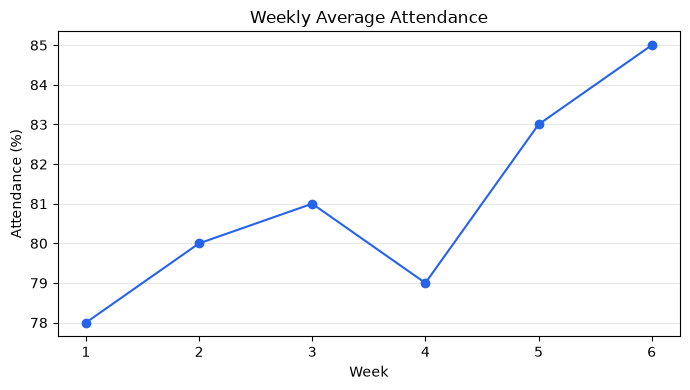

In [9]:
weeks = [1, 2, 3, 4, 5, 6] 
average_attendance = [78, 80, 81, 79, 83, 85] 
 
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(weeks, average_attendance, marker="o", color="#2563EB") 
ax.set(title="Weekly Average Attendance", xlabel="Week", ylabel="Attendance (%)") 
ax.set_xticks(weeks) 
ax.grid(axis="y", alpha=0.3) 
fig.tight_layout()

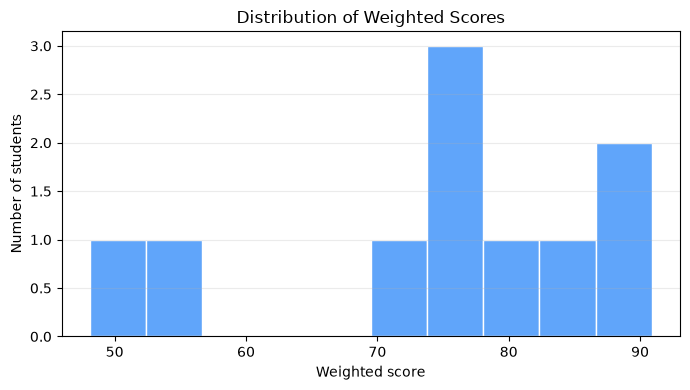

In [8]:
fig, ax = plt.subplots(figsize=(7, 4)) 
ax.hist(students["weighted_score"].dropna(), bins=10, 
        color="#60A5FA", edgecolor="white") 
ax.set(title="Distribution of Weighted Scores", 
       xlabel="Weighted score", ylabel="Number of students") 
ax.grid(axis="y", alpha=0.25) 
fig.tight_layout() 

C:\Users\hp\AppData\Local\Temp\ipykernel_11200\261738369.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(students["weighted_score"].dropna(), vert=False)


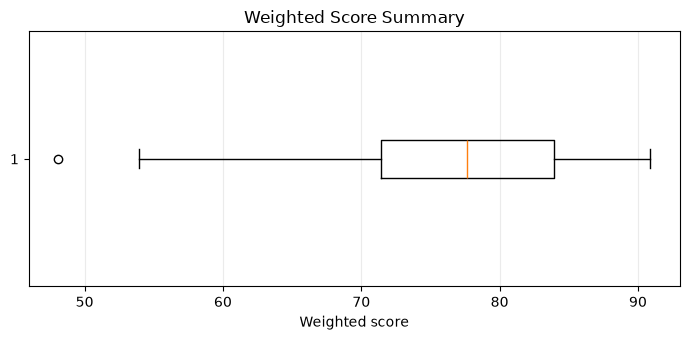

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5)) 
ax.boxplot(students["weighted_score"].dropna(), vert=False) 
ax.set(title="Weighted Score Summary", xlabel="Weighted score") 
ax.grid(axis="x", alpha=0.25) 
fig.tight_layout()

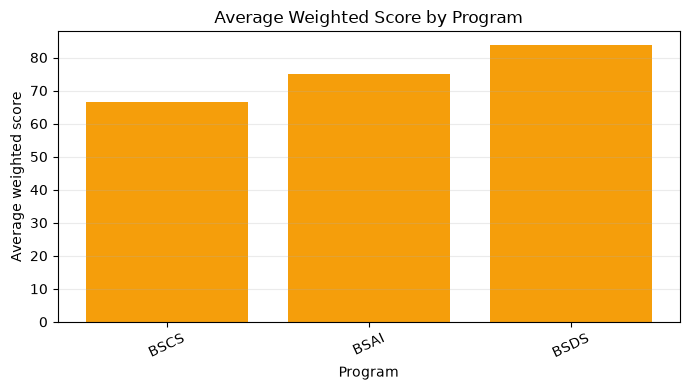

In [11]:
program_scores = (students.groupby("program")["weighted_score"] 
                  .mean().sort_values()) 
fig, ax = plt.subplots(figsize=(7, 4)) 
ax.bar(program_scores.index, program_scores.values, color="#F59E0B") 
ax.set(title="Average Weighted Score by Program", 
       xlabel="Program", ylabel="Average weighted score") 
ax.tick_params(axis="x", rotation=25) 
ax.grid(axis="y", alpha=0.25) 
fig.tight_layout() 

C:\Users\hp\AppData\Local\Temp\ipykernel_11200\3630106656.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, 1].boxplot(students["weighted_score"].dropna(), vert=False)


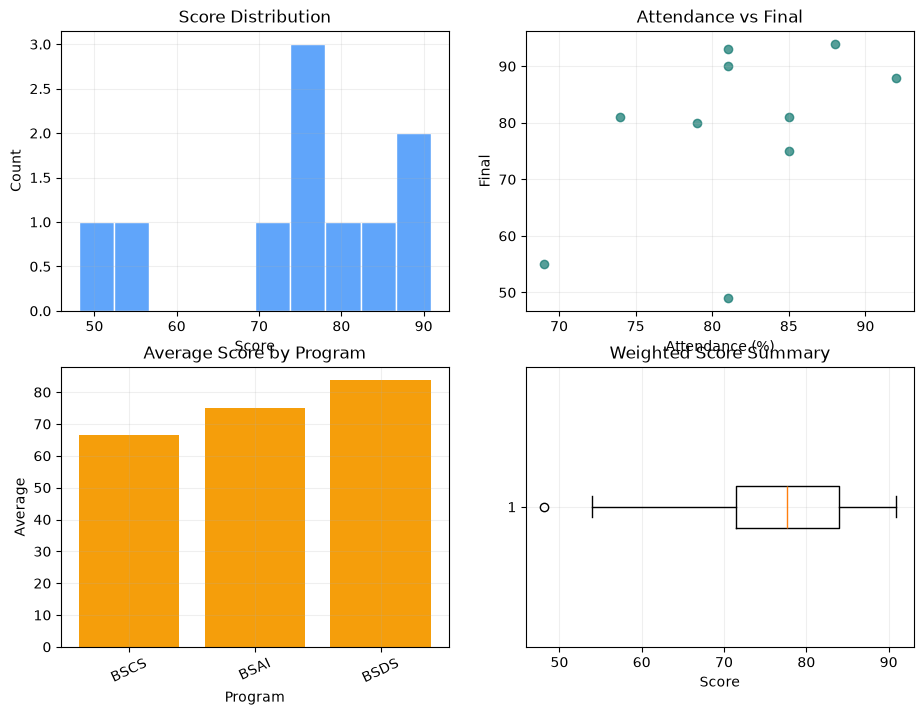

In [12]:
ig, axes = plt.subplots(2, 2, figsize=(11, 8)) 
 
axes[0, 0].hist(students["weighted_score"].dropna(), bins=10,color="#60A5FA",edgecolor="white") 
axes[0, 0].set(title="Score Distribution", xlabel="Score", ylabel="Count") 
 
axes[0, 1].scatter(students["attendance"], students["final"], alpha=0.7, color="#0F766E") 
axes[0, 1].set(title="Attendance vs Final", xlabel="Attendance (%)", ylabel="Final") 
 
axes[1, 0].bar(program_scores.index, program_scores.values, color="#F59E0B") 
axes[1, 0].set(title="Average Score by Program", xlabel="Program", ylabel="Average") 
axes[1, 0].tick_params(axis="x", rotation=25) 
 
axes[1, 1].boxplot(students["weighted_score"].dropna(), vert=False) 
axes[1, 1].set(title="Weighted Score Summary", xlabel="Score") 
 
for ax in axes.flat: 
    ax.grid(alpha=0.2) 
fig.suptitle("Student Performance Dashboard", fontsize=15, fontweight="bold") 
fig.tight_layout(rect=[0, 0, 1, 0.96]) 

In [13]:
png_path = FIGURE_DIR / "student_dashboard.png" 
pdf_path = FIGURE_DIR / "student_dashboard.pdf" 
fig.savefig(png_path, dpi=300, bbox_inches="tight") 
fig.savefig(pdf_path, bbox_inches="tight") 
plt.close(fig) 
assert png_path.exists() and png_path.stat().st_size > 0 
assert pdf_path.exists() and pdf_path.stat().st_size > 0 

In [ ]:
!git status
!git add week7 pyproject.toml uv.lock
!git commit -m "Complete Week 7 Matplotlib visualization lab"
!git log --oneline -7
git add week7 pyproject.toml uv.lock 
git commit -m "Complete Week 7 Matplotlib visualization lab"
git log --oneline -7 

SyntaxError: invalid syntax (1303433462.py, line 1)